   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

C:\Users\Siddhant\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Siddhant\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Siddhant\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Siddhant\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

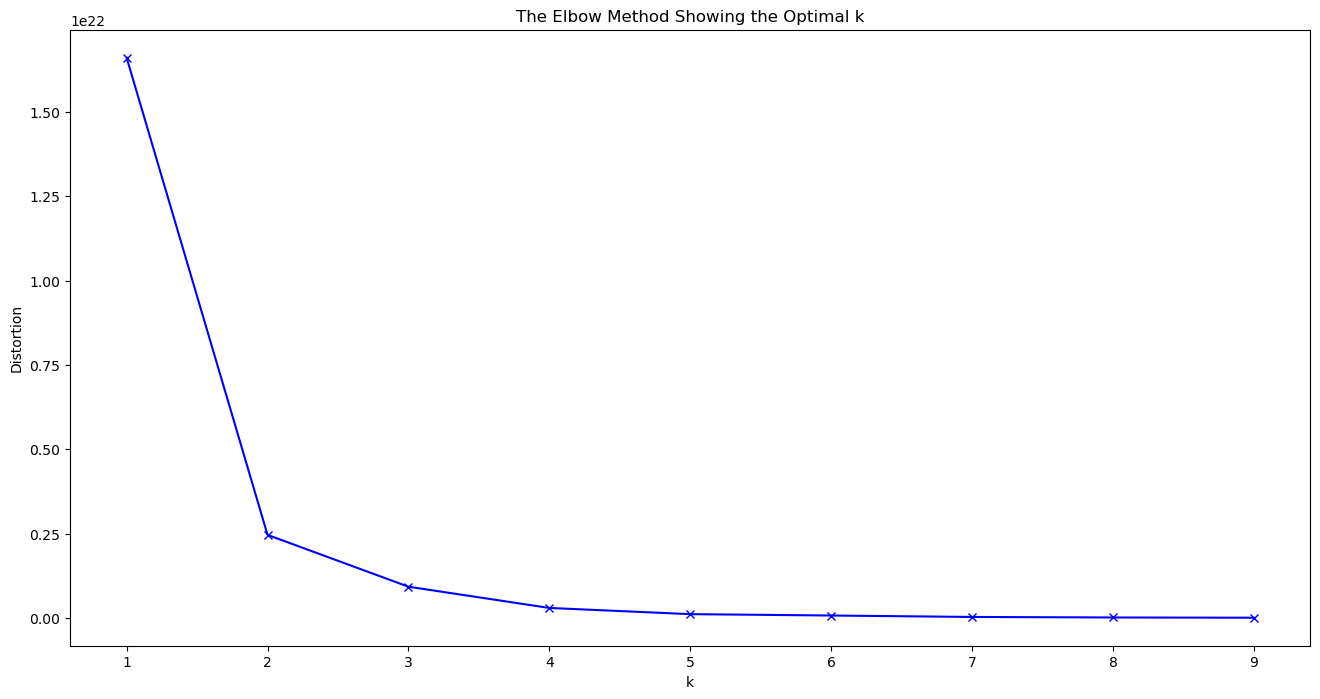


Number of observations in each cluster:
   Cluster1  Cluster2  Cluster3
0      1819       430       574


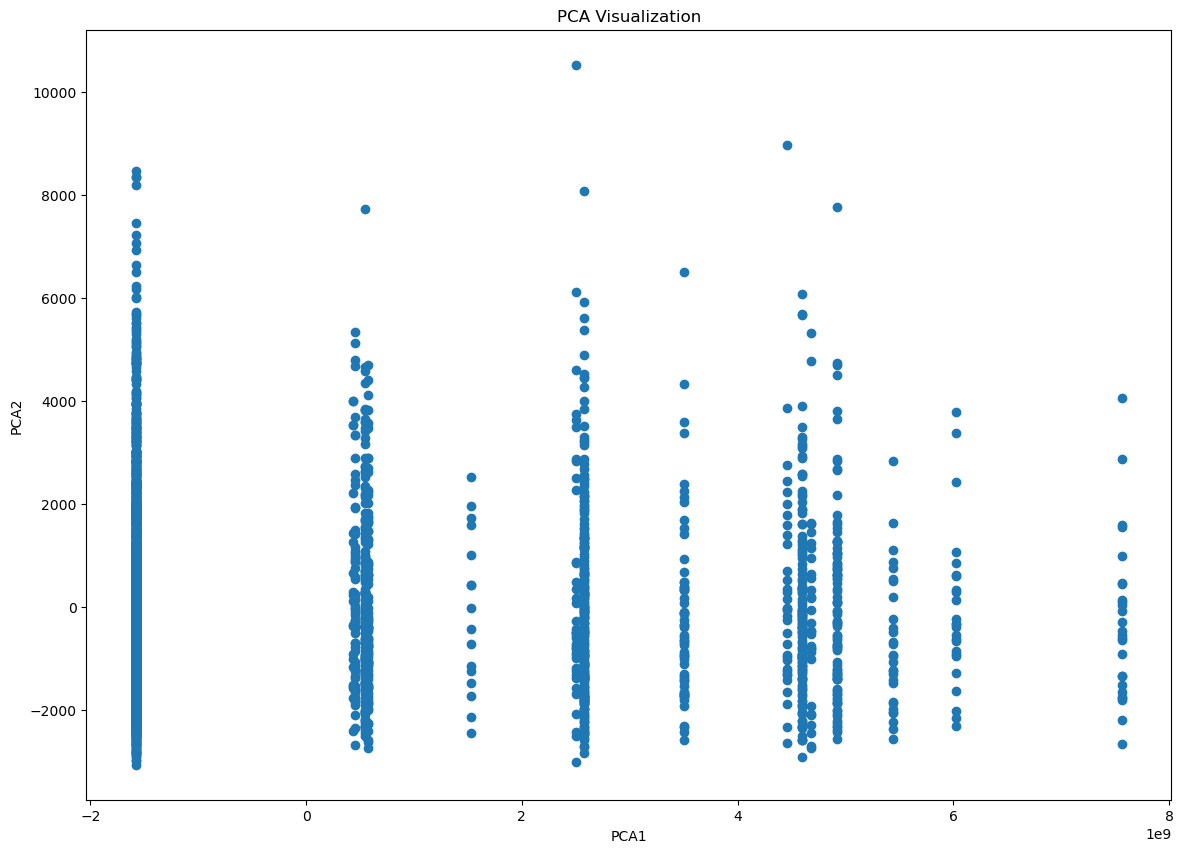


Cluster centroids:
[[1.02600434e+04 3.48587136e+01 8.35670258e+01 6.53380979e+00
  3.52097087e+03 2.67069819e+00 6.94997251e+00 2.00382518e+03
  1.00484332e+02 5.44562947e+01 0.00000000e+00 4.05311584e-06
  0.00000000e+00 0.00000000e+00 0.00000000e+00 3.50742166e-01
  1.00054975e-01 1.15997801e-01 9.01594283e-02 2.85871358e-02
  1.03903244e-01 2.10555250e-01 5.11269929e-02 4.83232545e-01
  4.65640462e-01]
 [1.02449000e+04 3.51069767e+01 8.33284419e+01 6.62325581e+00
  3.49681170e+03 2.93023256e+00 7.66511628e+00 2.00369535e+03
  9.97511628e+01 5.28883721e+01 0.00000000e+00 6.40985854e+09
  0.00000000e+00 0.00000000e+00 0.00000000e+00 3.02325581e-01
  1.76744186e-01 1.11627907e-01 8.37209302e-02 1.16279070e-02
  8.60465116e-02 2.27906977e-01 4.65116279e-02 5.06976744e-01
  4.46511628e-01]
 [1.02649042e+04 3.58240418e+01 8.41958537e+01 6.13414634e+00
  3.70096481e+03 2.70731707e+00 7.11498258e+00 2.00387282e+03
  1.02170732e+02 5.22717770e+01 0.00000000e+00 2.97015354e+09
  0.00000000e+

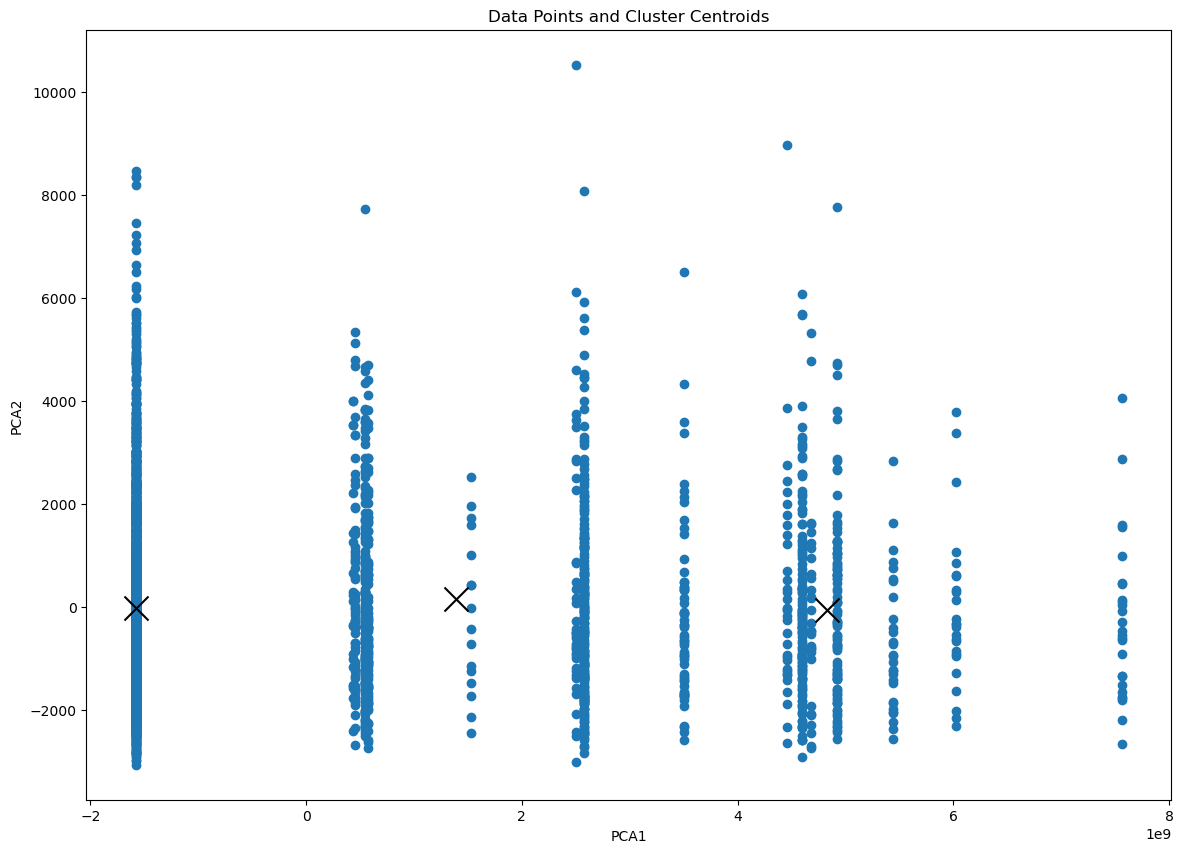


Clustered data:
           PCA1         PCA2  Clusters
0  5.452860e+08  -684.522341         2
1 -1.580272e+09  -782.924275         0
2 -1.580272e+09   335.497230         0
3  4.685285e+09   177.939504         1
4  4.925280e+09  1635.695510         1


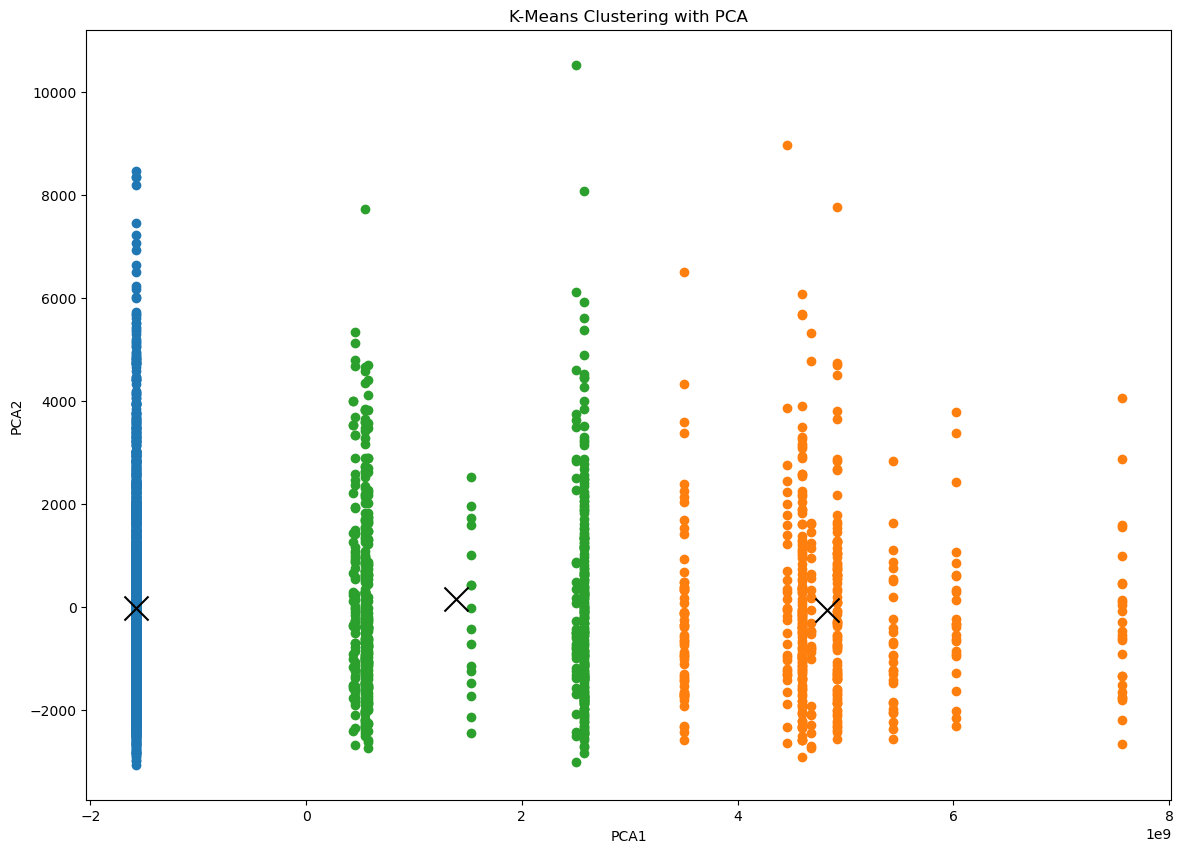

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Importing the dataset
df = pd.read_csv("sales_data_sample.csv", encoding="cp1252")

# Basic information
print(df.head())
print(df.shape)
print(df.describe())
print(df.info())
print(df.isnull().sum())
print(df.dtypes)

# --------------------------------------------------
# PREPROCESSING
# --------------------------------------------------

# Dropping unnecessary categorical columns
df_drop = [
    'ADDRESSLINE1',
    'ADDRESSLINE2',
    'STATUS',
    'POSTALCODE',
    'CITY',
    'TERRITORY'
]

df = df.drop(columns=df_drop)

# Check categorical columns
print(df['COUNTRY'].unique())
print(df['PRODUCTLINE'].unique())
print(df['DEALSIZE'].unique())

# One-hot encoding
productline = pd.get_dummies(df['PRODUCTLINE'], dtype=int)
dealsize = pd.get_dummies(df['DEALSIZE'], dtype=int)

df = pd.concat([df, productline, dealsize], axis=1)

# Drop original categorical columns
df = df.drop(
    columns=['COUNTRY', 'PRODUCTLINE', 'DEALSIZE']
)

# Convert PRODUCTCODE to numerical values
df['PRODUCTCODE'] = pd.Categorical(
    df['PRODUCTCODE']
).codes

# Drop ORDERDATE
df = df.drop(columns=['ORDERDATE'])

# Check datatypes
print("\nDatatypes after preprocessing:")
print(df.dtypes)

# Check remaining non-numeric columns
print("\nNon-numeric columns:")
print(df.select_dtypes(exclude=np.number).columns)

# Convert all remaining columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

# Handle missing values
df = df.fillna(0)

print("\nFinal shape:", df.shape)
print("\nFinal datatypes:")
print(df.dtypes)

# --------------------------------------------------
# ELBOW METHOD
# --------------------------------------------------

distortions = []

K = range(1, 10)

for k in K:

    kmeanModel = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeanModel.fit(df)

    distortions.append(kmeanModel.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(16, 8))

plt.plot(
    K,
    distortions,
    'bx-'
)

plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method Showing the Optimal k')

plt.show()

# --------------------------------------------------
# K-MEANS WITH 3 CLUSTERS
# --------------------------------------------------

X_train = df.values

model = KMeans(
    n_clusters=3,
    random_state=2,
    n_init=10
)

# Fit model
model.fit(X_train)

# Predict clusters
predictions = model.predict(X_train)

# Count observations in each cluster
unique, counts = np.unique(
    predictions,
    return_counts=True
)

counts_df = pd.DataFrame(
    [counts],
    columns=['Cluster1', 'Cluster2', 'Cluster3']
)

print("\nNumber of observations in each cluster:")
print(counts_df)

# --------------------------------------------------
# PCA FOR VISUALIZATION
# --------------------------------------------------

pca = PCA(n_components=2)

reduced_X = pd.DataFrame(
    pca.fit_transform(X_train),
    columns=['PCA1', 'PCA2']
)

# --------------------------------------------------
# NORMAL PCA SCATTER PLOT
# --------------------------------------------------

plt.figure(figsize=(14, 10))

plt.scatter(
    reduced_X['PCA1'],
    reduced_X['PCA2']
)

plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.title('PCA Visualization')

plt.show()

# --------------------------------------------------
# CLUSTER CENTROIDS
# --------------------------------------------------

centers = model.cluster_centers_

print("\nCluster centroids:")
print(centers)

# Transform centroids into PCA space
reduced_centers = pca.transform(centers)

print("\nPCA coordinates of centroids:")
print(reduced_centers)

# --------------------------------------------------
# DATA + CENTROIDS
# --------------------------------------------------

plt.figure(figsize=(14, 10))

plt.scatter(
    reduced_X['PCA1'],
    reduced_X['PCA2']
)

plt.scatter(
    reduced_centers[:, 0],
    reduced_centers[:, 1],
    color='black',
    marker='x',
    s=300
)

plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.title('Data Points and Cluster Centroids')

plt.show()

# --------------------------------------------------
# ADD CLUSTER LABELS
# --------------------------------------------------

reduced_X['Clusters'] = predictions

print("\nClustered data:")
print(reduced_X.head())

# --------------------------------------------------
# PLOT THE CLUSTERS
# --------------------------------------------------

plt.figure(figsize=(14, 10))

# Cluster 0
plt.scatter(
    reduced_X[
        reduced_X['Clusters'] == 0
    ]['PCA1'],

    reduced_X[
        reduced_X['Clusters'] == 0
    ]['PCA2']
)

# Cluster 1
plt.scatter(
    reduced_X[
        reduced_X['Clusters'] == 1
    ]['PCA1'],

    reduced_X[
        reduced_X['Clusters'] == 1
    ]['PCA2']
)

# Cluster 2
plt.scatter(
    reduced_X[
        reduced_X['Clusters'] == 2
    ]['PCA1'],

    reduced_X[
        reduced_X['Clusters'] == 2
    ]['PCA2']
)

# Centroids
plt.scatter(
    reduced_centers[:, 0],
    reduced_centers[:, 1],
    color='black',
    marker='x',
    s=300
)

plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.title('K-Means Clustering with PCA')

plt.show()